# 40 - Previsão: o que se consegue prever, com que antecedência e com que confiança

| | |
|---|---|
| **Objetivo** | Passar dos alertas calculados sobre o passado para alertas **previstos** para os próximos dias |
| **O que faz** | Verifica as fontes de previsão, calcula os limites, treina e avalia os modelos de previsão e define as zonas de aviso |
| **Usa** | Previsões públicas de caudal e de chuva, 30 anos de histórico, mapas da cheia de 2026, série de turbidez |
| **Produz** | `models/limites_previsao.json`, `models/modelo_c_caudal.joblib`, `models/modelo_turbidez.joblib`, `models/mare_maputo.json`, zonas de aviso, tabelas em `reports/producao/` |

Precisa de internet só na primeira célula de dados (poucos MB, uma vez). Correr
uma vez, e de novo quando houver dados novos para treinar.

## O que se pode prever

| O quê | Como | Até quando | Confiança |
|---|---|---|---|
| Caudal do Incomáti em Marracuene | 51 cenários do modelo europeu GloFAS, que já inclui a previsão de chuva | 30 dias; fiável sobretudo nos primeiros 7 a 10 | a melhor fonte disponível; não a pudemos testar com previsões antigas |
| Caudal, segunda opinião | modelo próprio (Modelo C), só com a chuva que já caiu | 1 a 7 dias | medida neste notebook em 2022–2026 |
| Chuva na bacia | previsão do centro europeu (ECMWF) | 16 dias; usada como gatilho só até 7 | a previsão de chuva perde qualidade depressa com os dias |
| Nível de alerta | caudal e chuva previstos contra os limites | 10 dias | herda a das previsões acima |
| Turbidez da água (índice de cor) | medição por satélite a cada 5 dias; previsão com caudal, maré e última medição | manhãs dos próximos 10 dias, em três troços | AUC 0,87 a 0,89 em anos não vistos; 0,88 noutro satélite e noutros anos (notebook 35) |
| Onde a água chega | zonas onde chegou na cheia de janeiro de 2026 | fixo | um evento de referência |

**O que não se prevê:** o dia exato em que a água chega a cada bairro, nem a
qualidade química ou bacteriológica da água.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, forecast, forecast_models, operations, rasters
from ete import grid as G

cfg = config.load_config()
F = cfg["forecast"]
REPORTS = config.path(cfg, "reports", "producao")
LEVEL_COLOURS = {0: "#2ecc71", 1: "#f1c40f", 2: "#e67e22", 3: "#c0392b"}
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. A fonte da previsão de caudal é coerente com os nossos dados?

A previsão vem do serviço Open-Meteo, que distribui gratuitamente o GloFAS (o
mesmo modelo dos dados de caudal da Semana 1). A grelha do serviço está
deslocada uma célula em relação aos nossos ficheiros, por isso a célula do rio
foi procurada de novo e está fixada no config (`forecast.discharge_point`).
A comparação abaixo confirma que as duas séries contam a mesma história.

/tmp/ipykernel_598901/4246054146.py:4: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat([ours, history["q"].shift(1)], axis=1, keys=["nossos ficheiros GloFAS", "serviço de previsão"]).dropna()


histórico do serviço: 1997-01-01 a 2026-10-11
7,581 dias em comum | correlação 0.983 | médias 55.4 e 55.4 m³/s


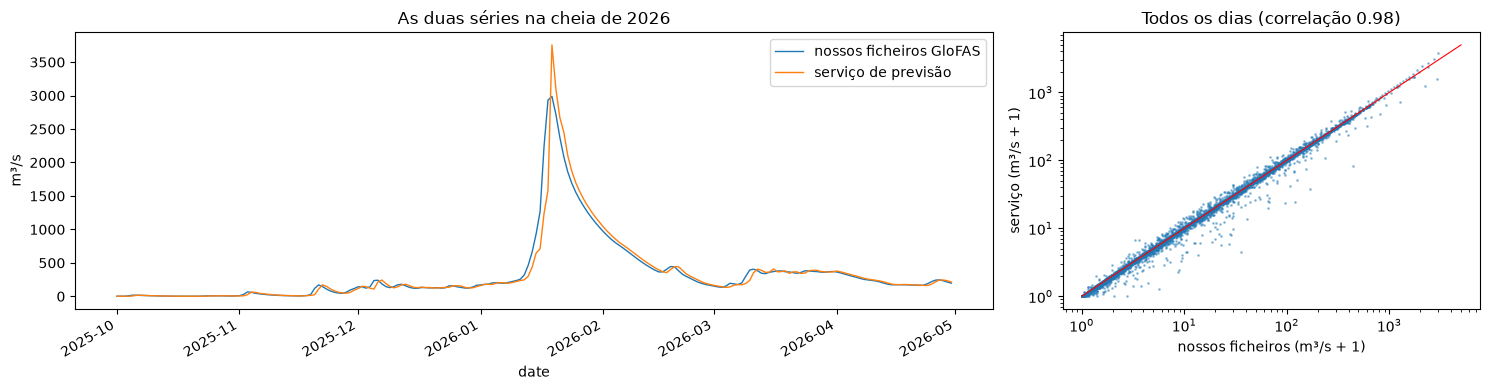

In [2]:
forecast.update_history(cfg)                       # internet: só descarrega os dias em falta
history = forecast.load_history(cfg)
ours = drivers.read_table(cfg, "hydromet_daily")["discharge_m3s"].dropna()
both = pd.concat([ours, history["q"].shift(1)], axis=1, keys=["nossos ficheiros GloFAS", "serviço de previsão"]).dropna()
r = both.corr().iloc[0, 1]
print(f"histórico do serviço: {history['q'].first_valid_index().date()} a {history['q'].last_valid_index().date()}")
print(f"{len(both):,} dias em comum | correlação {r:.3f} | médias {both.iloc[:, 0].mean():.1f} e {both.iloc[:, 1].mean():.1f} m³/s")

fig, axes = plt.subplots(1, 2, figsize=(15, 4), width_ratios=[2.2, 1])
both.loc["2025-10":"2026-04"].plot(ax=axes[0], linewidth=1); axes[0].set_ylabel("m³/s"); axes[0].set_title("As duas séries na cheia de 2026")
axes[1].loglog(both.iloc[:, 0] + 1, both.iloc[:, 1] + 1, ".", markersize=2, alpha=0.4); axes[1].plot([1, 5000], [1, 5000], color="red", linewidth=0.8)
axes[1].set_xlabel("nossos ficheiros (m³/s + 1)"); axes[1].set_ylabel("serviço (m³/s + 1)"); axes[1].set_title(f"Todos os dias (correlação {r:.2f})")
plt.tight_layout(); plt.savefig(REPORTS / "40_fonte_de_previsao.png", dpi=110)

## 2. Limites dos alertas para a previsão

São os mesmos critérios do motor de alertas (notebook 32), recalculados sobre o
histórico do próprio serviço de previsão, para que previsão e limites venham da
mesma fonte. Usam só dados até 2021; ficam guardados em
`models/limites_previsao.json` e cada boletim regista com que limites foi feito.

calibração: ['1997-01-01', '2021-12-31'] | limites de caudal (m³/s): {'amarelo': 163.8, 'laranja': 375.8, 'vermelho': 969.9}


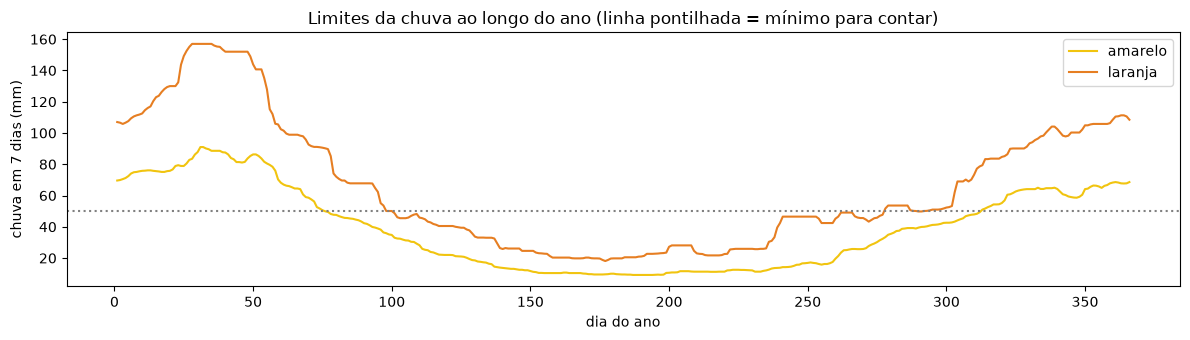

In [3]:
limits = forecast.build_limits(cfg)
print("calibração:", limits["calibration"], "| limites de caudal (m³/s):", limits["discharge_m3s"])
rain_limits = pd.DataFrame(limits["rain_p7_mm_by_doy"]).T.astype(float); rain_limits.index = rain_limits.index.astype(int)
ax = rain_limits.sort_index().plot(figsize=(12, 3.5), color=["#f1c40f", "#e67e22"])
ax.axhline(limits["rain_p7_min_mm"], color="grey", linestyle=":"); ax.set_xlabel("dia do ano"); ax.set_ylabel("chuva em 7 dias (mm)")
ax.set_title("Limites da chuva ao longo do ano (linha pontilhada = mínimo para contar)")
plt.tight_layout(); plt.savefig(REPORTS / "40_limites_da_chuva.png", dpi=110)

## 3. Se as previsões acertassem sempre: o teto do sistema

Não existe arquivo público das previsões antigas, por isso não se pode medir
quantas vezes a previsão de há cinco dias acertou. O que se pode fazer é aplicar
os limites ao caudal e à chuva que **realmente ocorreram**. É o melhor resultado
possível: o sistema real fica algures abaixo disto.

,primeiro_alerta,dias_de_antecedencia,nivel_no_dia
jan 2026: primeira cheia mapeada em Marracuene,2026-01-13,4,vermelho
jan 2026: maior extensão mapeada,2026-01-13,11,vermelho
fev 2023: ativação do Copernicus para Maputo,2023-02-09,2,vermelho


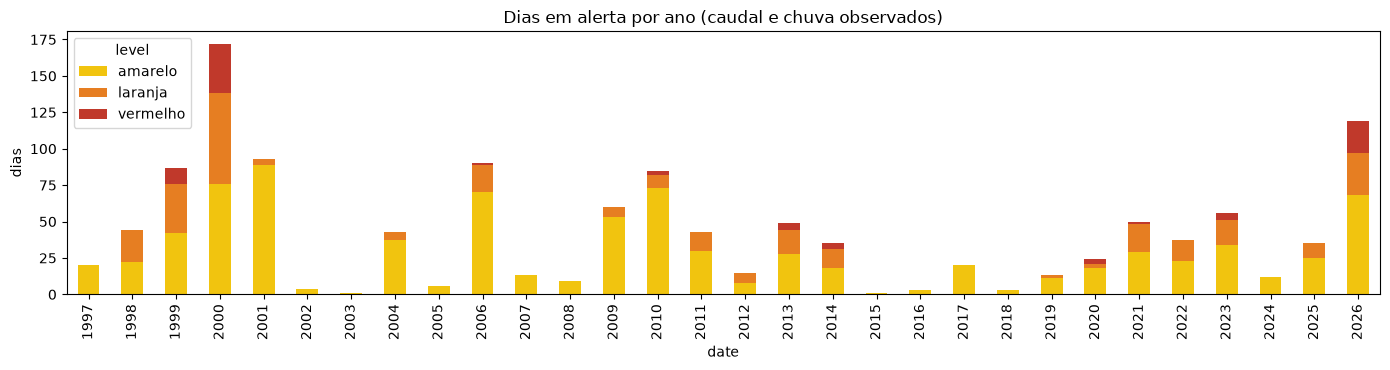

In [4]:
perfect = forecast.perfect_forecast_backtest(cfg, limits)
per_year = perfect.groupby(perfect.index.year)["level"].value_counts().unstack(fill_value=0).rename(columns=alerts.LEVELS)
ax = per_year[["amarelo", "laranja", "vermelho"]].plot.bar(stacked=True, figsize=(14, 3.8), color=["#f1c40f", "#e67e22", "#c0392b"], ylabel="dias", title="Dias em alerta por ano (caudal e chuva observados)")
plt.tight_layout(); plt.savefig(REPORTS / "40_dias_em_alerta.png", dpi=110)

events = {"jan 2026: primeira cheia mapeada em Marracuene": "2026-01-17", "jan 2026: maior extensão mapeada": "2026-01-24",
          "fev 2023: ativação do Copernicus para Maputo": "2023-02-11"}
lead = pd.DataFrame({name: alerts.lead_time(perfect, day) for name, day in events.items()}).T
lead.to_csv(REPORTS / "40_antecedencia_teto.csv")
lead

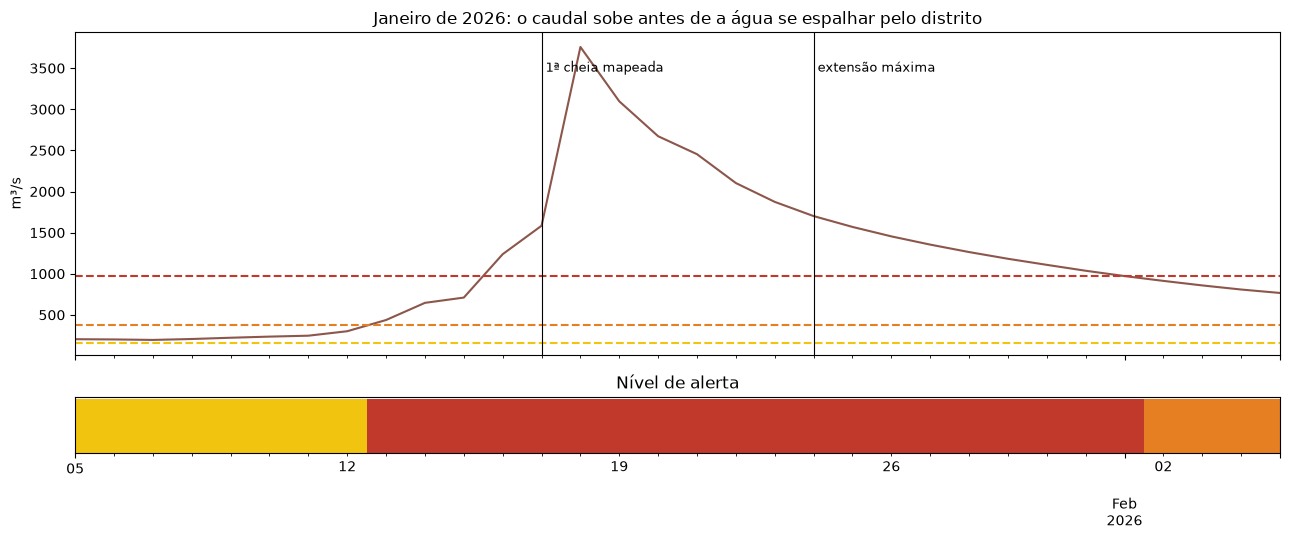

In [5]:
window = perfect.loc["2026-01-05":"2026-02-05"]
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, height_ratios=[4, 0.7])
window["caudal"].plot(ax=axes[0], color="tab:brown")
for name, value in limits["discharge_m3s"].items():
    axes[0].axhline(value, color={"amarelo": "#f1c40f", "laranja": "#e67e22", "vermelho": "#c0392b"}[name], linestyle="--")
for day, label in [("2026-01-17", "1ª cheia mapeada"), ("2026-01-24", "extensão máxima")]:
    axes[0].axvline(pd.Timestamp(day), color="black", linewidth=0.8); axes[0].text(pd.Timestamp(day), window["caudal"].max() * 0.92, " " + label, fontsize=9)
axes[0].set_ylabel("m³/s"); axes[0].set_title("Janeiro de 2026: o caudal sobe antes de a água se espalhar pelo distrito")
axes[1].bar(window.index, 1, width=1, color=[LEVEL_COLOURS[v] for v in window["level"]]); axes[1].set_yticks([]); axes[1].set_title("Nível de alerta")
plt.tight_layout(); plt.savefig(REPORTS / "40_janeiro_2026.png", dpi=110)

**O que este episódio ensina.** O caudal passou o limite laranja a 13 de janeiro.
A primeira cheia foi mapeada no distrito a 17, e a maior extensão só a 23 e 24.
A água demora dias a espalhar-se pela planície: mesmo um alerta dado no próprio
dia em que o caudal sobe ainda deixa tempo para agir. Com a previsão, esse tempo
aumenta.

## 4. Modelo C: a nossa segunda opinião sobre o caudal

Um modelo treinado por nós (XGBoost, dados de 1997 a 2021) que prevê o caudal a
1, 2, 3, 5 e 7 dias a partir do caudal dos últimos dias e da chuva **já caída**
na bacia. Não usa previsão de chuva. É comparado com a previsão mais simples
possível: "o caudal fica como está hoje" (persistência).

,dias_de_teste,nse_modelo,pod_modelo,far_modelo,csi_modelo,nse_persistencia,pod_persistencia,far_persistencia,csi_persistencia
dias_a_frente,,,,,,,,,
1,1738,0.92,0.91,0.12,0.81,0.90,0.86,0.14,0.76
2,1737,0.83,0.81,0.16,0.70,0.75,0.76,0.24,0.61
3,1736,0.70,0.73,0.16,0.64,0.61,0.72,0.28,0.56
5,1734,0.54,0.61,0.20,0.53,0.39,0.63,0.37,0.46
7,1732,0.44,0.62,0.16,0.56,0.21,0.61,0.39,0.44


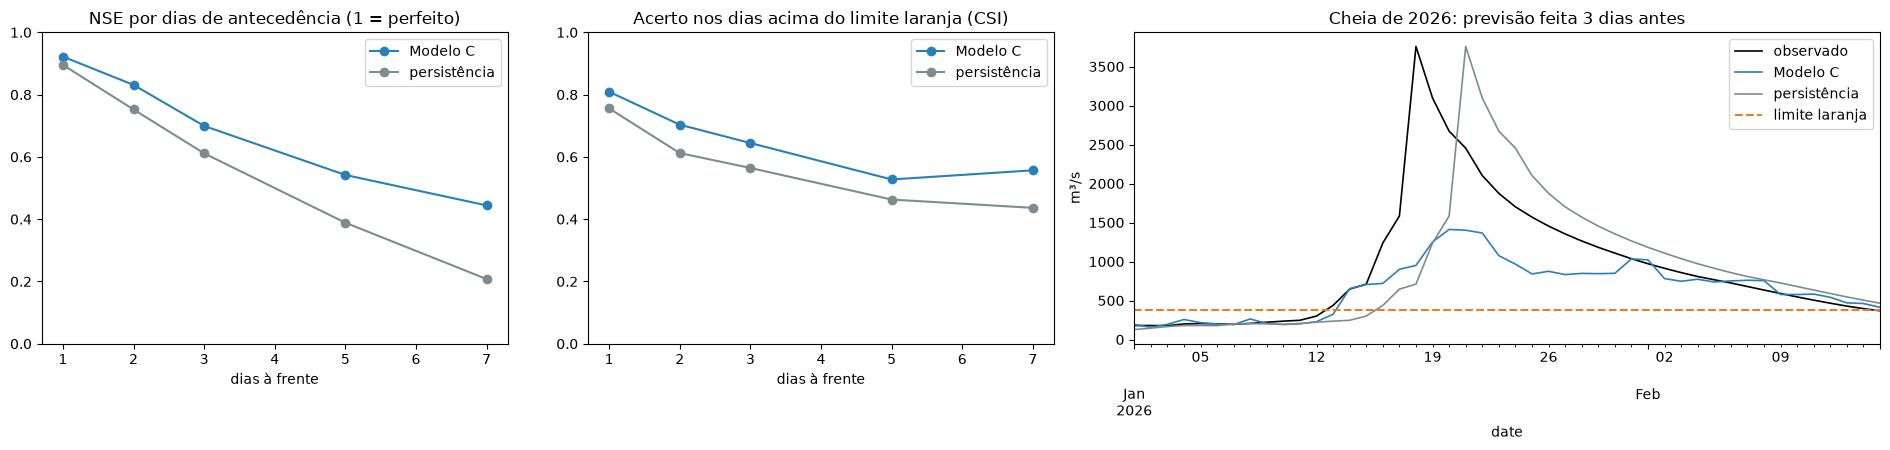

In [6]:
skill = forecast_models.fit_discharge_model(cfg)
skill.round(3).to_csv(REPORTS / "40_modelo_c_desempenho.csv")
series = skill.attrs["test_series"]

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), width_ratios=[1, 1, 1.6])
skill[["nse_modelo", "nse_persistencia"]].plot(ax=axes[0], marker="o", color=["#2980b9", "#7f8c8d"]); axes[0].set_ylim(0, 1)
axes[0].set_title("NSE por dias de antecedência (1 = perfeito)"); axes[0].legend(["Modelo C", "persistência"]); axes[0].set_xlabel("dias à frente")
skill[["csi_modelo", "csi_persistencia"]].plot(ax=axes[1], marker="o", color=["#2980b9", "#7f8c8d"]); axes[1].set_ylim(0, 1)
axes[1].set_title("Acerto nos dias acima do limite laranja (CSI)"); axes[1].legend(["Modelo C", "persistência"]); axes[1].set_xlabel("dias à frente")
series[3].loc["2026-01-01":"2026-02-15"].plot(ax=axes[2], color=["black", "#2980b9", "#7f8c8d"], linewidth=1.2)
axes[2].axhline(limits["discharge_m3s"]["laranja"], color="#e67e22", linestyle="--"); axes[2].set_ylabel("m³/s")
axes[2].set_title("Cheia de 2026: previsão feita 3 dias antes"); axes[2].legend(["observado", "Modelo C", "persistência", "limite laranja"])
plt.tight_layout(); plt.savefig(REPORTS / "40_modelo_c.png", dpi=110)
skill.round(2)

**Como ler**

- **NSE:** 1 é perfeito; 0 é tão bom como dizer sempre a média. **CSI:** dos dias em
  que o caudal esteve acima do limite laranja, ou foi previsto acima, que parte
  foi acerto.
- O Modelo C é melhor do que a persistência em todas as antecedências, e a
  vantagem cresce com os dias. A 1 dia os dois são quase iguais.
- **Limite importante:** na subida de uma cheia o modelo fica atrás do que
  acontece (gráfico da direita). Só com a chuva já caída não se adivinha a chuva
  que ainda vai cair. É por isso que a previsão principal usa os cenários do
  GloFAS, que incluem a previsão de chuva; o Modelo C serve de verificação e de
  recurso quando o serviço falhar.

## 5. Turbidez: medição e previsão

Os testes da turbidez estão no notebook 35. O que entra na produção:

- A **medição** por satélite (índice de cor NDTI) é repetível: dois satélites
  independentes concordam no mesmo dia.
- A **previsão** usa um modelo com o caudal, a chuva, a época do ano, a maré
  calculada para a hora do satélite e a última medição por satélite do troço.
  Sem a maré o modelo não ganhava à época do ano.
- Vale para a manhã (hora de passagem do satélite) e para os três troços em que
  a medição é fiável.

A tabela é a que foi guardada com o modelo quando ele foi treinado (notebook 35).

,dias,r2,mae,auc,bss
modelo,,,,,
modelo final: última medição há 1 dia ou mais,2211,0.68,0.04,0.89,0.30
modelo final: última medição há 3 dias ou mais,2211,0.67,0.04,0.88,0.28
modelo final: última medição há 5 dias ou mais,2211,0.67,0.04,0.87,0.26
modelo final: última medição há 10 dias ou mais,2211,0.65,0.04,0.88,0.27
modelo final: sem medição recente,2211,0.61,0.05,0.85,0.20
passo anterior: maré só pela fase M2,2211,0.60,0.05,0.84,0.20
sem maré,2211,0.19,0.07,0.74,-0.04
referência: época do ano,2211,0.21,0.07,0.71,NaN
modelo final no Landsat 8/9 (outro satélite): todos os anos,739,0.65,0.04,0.90,NaN


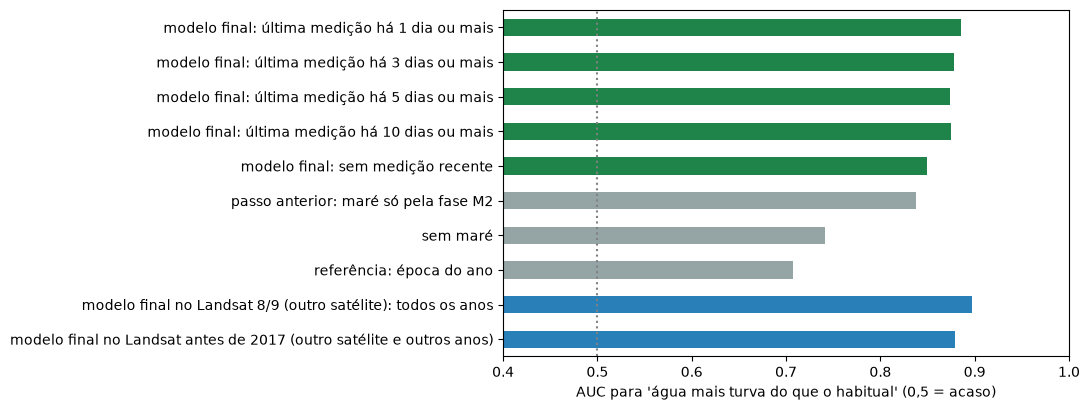

In [7]:
t_skill = forecast_models.turbidity_skill(cfg)
t_skill.round(3).to_csv(REPORTS / "40_turbidez_desempenho.csv")
colour = ["#1e8449" if n.startswith("modelo final:") else "#2980b9" if "Landsat" in n else "#95a5a6" for n in t_skill.index]
ax = t_skill["auc"].plot.barh(figsize=(11, 4.2), color=colour); ax.invert_yaxis(); ax.set_ylabel("")
ax.axvline(0.5, color="grey", linestyle=":"); ax.set_xlim(0.4, 1); ax.set_xlabel("AUC para 'água mais turva do que o habitual' (0,5 = acaso)")
plt.tight_layout(); plt.savefig(REPORTS / "40_turbidez_desempenho.png", dpi=110)
t_skill.round(3)

A verde, o modelo final conforme a idade da última medição por satélite. A azul,
o teste mais exigente: o modelo, treinado só com o Sentinel-2, a prever os dias
medidos pelo Landsat.

## 6. Zonas de aviso: onde a água chega

O mapa de suscetibilidade do Modelo A ordena bem o risco, mas as suas classes
são largas demais para dizer a quem avisar: a classe "média" tem mais de 50 mil
edifícios e só uma pequena parte alagou em 2026. Para os avisos usa-se por isso
o que foi **observado** na cheia de referência (janeiro de 2026, Copernicus):

- **Zona 1**: alagada logo nos primeiros mapas (17 e 18 de janeiro). São os
  primeiros sítios a ficar debaixo de água. Avisada a partir do nível amarelo.
- **Zona 2**: alagada na maior extensão (23 e 24 de janeiro). Avisada no nível
  vermelho.

Fora da área que o Copernicus analisou (o sul do distrito) não há extensão
observada; aí usam-se as classes "muito alta" e "alta" do Modelo A.

data/processed/maps/zonas_de_aviso/zonas_de_aviso_marracuene.gpkg


,area_km2,area_agricola_km2,edificios,escolas,unidades_de_saude,estradas_km
zona,,,,,,
zona 1 (primeiras a alagar),42.50,11.70,40,0,0,5.40
zonas 1 e 2 (cheia grande),238.60,46.30,1935,1,1,231.70


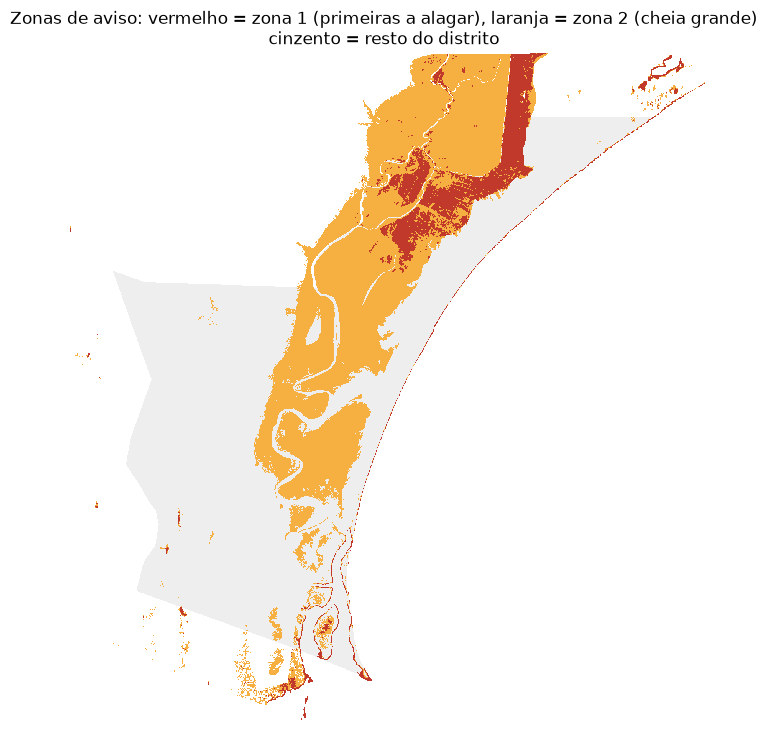

In [8]:
zones = alerts.warning_zones(cfg)
exposure = alerts.exposure_by_zone(cfg, zones["raster"])
exposure.round(1).to_csv(config.path(cfg, "forecast", "exposicao_por_zona.csv"))
exposure.round(1).to_csv(REPORTS / "40_exposicao_por_zona.csv")

from matplotlib.colors import ListedColormap
district = rasters.study_masks(cfg)["district"]
shown = np.where(zones["raster"] > 0, zones["raster"], np.nan).astype("float32")
fig, ax = plt.subplots(figsize=(7, 8))
ax.imshow(np.where(district, 0.0, np.nan), cmap=ListedColormap(["#eeeeee"]), interpolation="nearest")
ax.imshow(shown, cmap=ListedColormap(["#c0392b", "#f5b041"]), vmin=1, vmax=2, interpolation="nearest")
ax.set_title("Zonas de aviso: vermelho = zona 1 (primeiras a alagar), laranja = zona 2 (cheia grande)\ncinzento = resto do distrito"); ax.axis("off")
plt.tight_layout(); plt.savefig(REPORTS / "40_zonas_de_aviso.png", dpi=110)
print(zones["file"].relative_to(ROOT))
exposure.round(1)

**Como ler a tabela.** As linhas são cumulativas. A cheia do Incomáti atinge
sobretudo **terras agrícolas e caminhos**: o impacto na comunidade é mais em
culturas, gado e acessos cortados do que em casas. Os edifícios contam os que
tocam na zona, incluindo anexos e construções agrícolas.

## 7. Os lugares pelo nome: quem alaga primeiro

As pessoas não leem "zona 1" e "zona 2": conhecem o nome do sítio onde vivem. A
tabela junta os nomes dos lugares (OpenStreetMap e o dicionário geográfico
público GeoNames) às zonas de aviso. Cada lugar é um ponto com um círculo de
500 m à volta. A ordem vem da cheia de janeiro de 2026: em que mapa do
Copernicus a água aparece pela primeira vez nesse círculo.

In [9]:
from ete import places

lugares = places.flood_order(cfg)
resumo = lugares["categoria"].value_counts().reindex(places.CATEGORIES).to_frame("lugares")
display(resumo)
cols = ["lugar", "posto_administrativo", "categoria", "primeira_data", "dias_apos_alerta", "parte_alagada", "edificios", "edificios_alagados", "distancia_ao_rio_m", "altura_acima_do_rio_m"]
lugares.loc[lugares["categoria"].isin(places.CATEGORIES[:2]), cols]

,lugares
categoria,
alaga primeiro,4
alaga em cheia grande,18
na margem da cheia,23
fora das zonas de aviso,41


,lugar,posto_administrativo,categoria,primeira_data,dias_apos_alerta,parte_alagada,edificios,edificios_alagados,distancia_ao_rio_m,altura_acima_do_rio_m
0,Machavo,Machubo,alaga primeiro,2026-01-17,4.00,0.82,45,0,"6,730.00",4.00
1,Macanda,Machubo,alaga primeiro,2026-01-17,4.00,0.82,45,0,"6,730.00",4.00
2,Macanda,Machubo,alaga primeiro,2026-01-17,4.00,0.53,62,0,"7,270.00",4.90
3,Machubo,Machubo,alaga primeiro,2026-01-17,4.00,0.11,255,0,"6,790.00",15.40
4,Mecaline,Marracuene,alaga em cheia grande,2026-01-23,10.00,0.86,42,10,790.00,1.10
5,Aldeia Verde,Marracuene,alaga em cheia grande,2026-01-23,10.00,0.78,12,12,0.00,0.90
6,M. Pateque,Marracuene,alaga em cheia grande,2026-01-23,10.00,0.71,157,43,660.00,3.70
7,Incanine,Marracuene,alaga em cheia grande,2026-01-23,10.00,0.69,62,11,30.00,3.10
8,D’lhelo,Machubo,alaga em cheia grande,2026-01-23,10.00,0.65,54,1,"2,490.00",2.80
9,Augusto Sa,Marracuene,alaga em cheia grande,2026-01-23,10.00,0.56,20,20,0.00,1.30


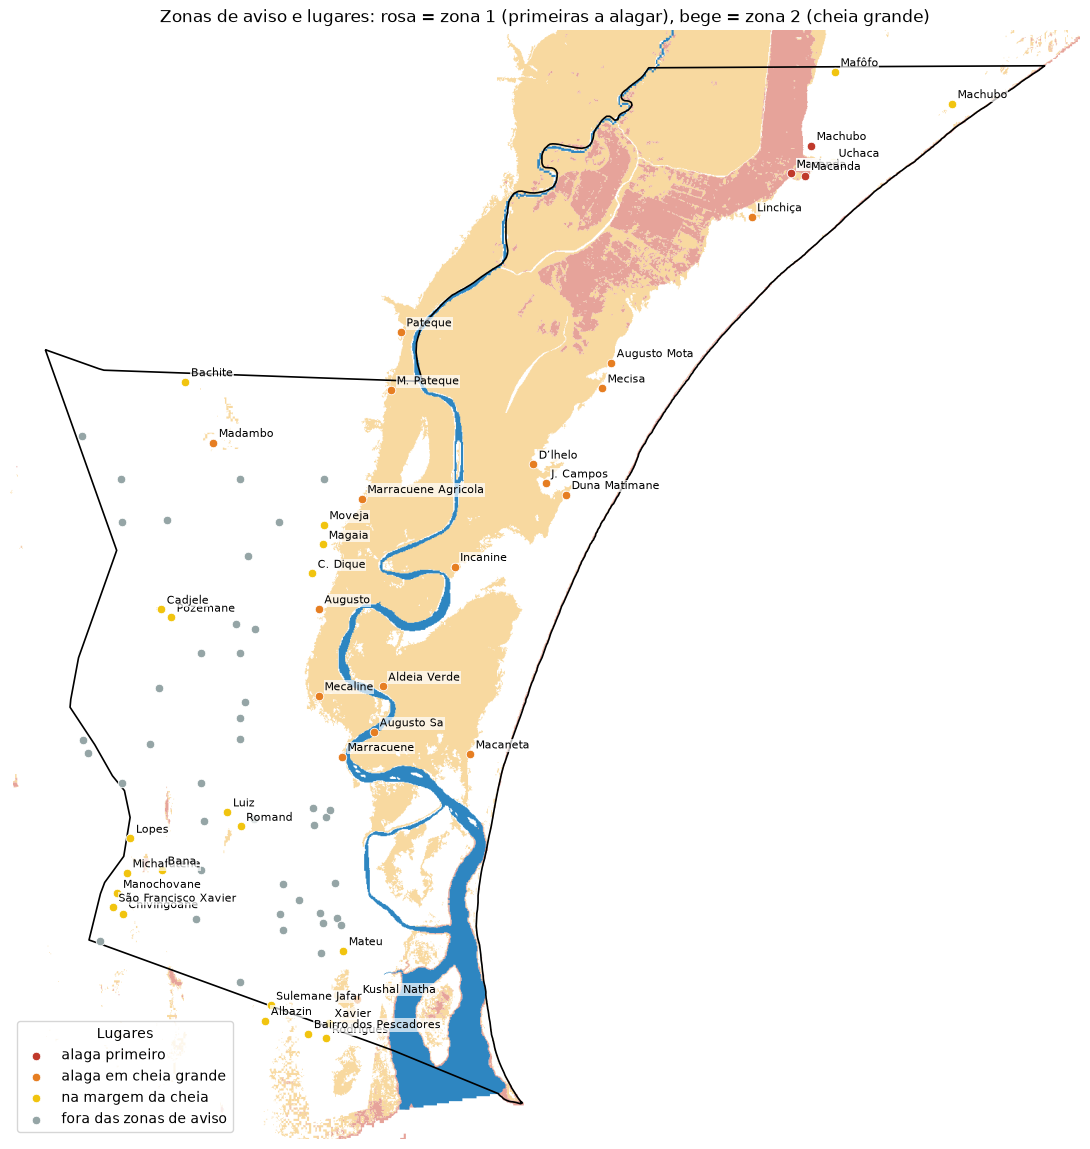

In [10]:
import geopandas as gpd

name = cfg["project"]["aoi_name"]
zonas = gpd.read_file(config.path(cfg, "maps", "zonas_de_aviso", f"zonas_de_aviso_{name}.gpkg", mkdir=False))
rio = gpd.read_file(config.path(cfg, "features", f"river_channel_{name}.gpkg", mkdir=False))
distrito = G.load_aoi(cfg, "district").to_crs(zonas.crs)
palette = {"alaga primeiro": "#c0392b", "alaga em cheia grande": "#e67e22", "na margem da cheia": "#f1c40f", "fora das zonas de aviso": "#95a5a6"}

fig, ax = plt.subplots(figsize=(11, 12.5))
zonas[zonas["zona"] == 2].plot(ax=ax, color="#f8d9a0"); zonas[zonas["zona"] == 1].plot(ax=ax, color="#e6a39a")
rio.plot(ax=ax, color="#2e86c1"); distrito.boundary.plot(ax=ax, color="black", linewidth=1.2)
for category, colour in palette.items():
    part = lugares[lugares["categoria"] == category]
    part.plot(ax=ax, color=colour, markersize=38, edgecolor="white", linewidth=0.6, label=category, zorder=3)
for _, row in lugares[lugares["categoria"].isin(places.CATEGORIES[:3])].iterrows():
    ax.annotate(row["lugar"], (row.geometry.x, row.geometry.y), xytext=(4, 4), textcoords="offset points", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.6))
west, south, east, north = distrito.total_bounds
ax.set_xlim(west - 1500, east + 1500); ax.set_ylim(south - 1500, north + 1500); ax.set_axis_off(); ax.legend(loc="lower left", title="Lugares")
ax.set_title("Zonas de aviso e lugares: rosa = zona 1 (primeiras a alagar), bege = zona 2 (cheia grande)")
plt.tight_layout(); plt.savefig(REPORTS / "40_lugares_e_zonas.png", dpi=120)

**Como usar com a comunidade**

- **Como corre uma cheia grande** (referência: janeiro de 2026): o alerta subiu a
  laranja a 13 de janeiro; os primeiros lugares tinham água a 17 (4 dias
  depois); a maior extensão foi mapeada a 23 e 24 (10 a 11 dias depois). A
  coluna `dias_apos_alerta` dá esse tempo para cada lugar.
- As datas são as dos mapas do Copernicus. Entre 18 e 23 de janeiro não houve
  mapa, por isso "dia 23" quer dizer "a água chegou entre 19 e 23".

**Antes de publicar, esta lista tem de ser revista por quem conhece Marracuene.**

- Muitos nomes vêm de um dicionário geográfico antigo: alguns são nomes de
  antigas propriedades agrícolas e podem já não ser usados; faltam bairros
  recentes.
- Um lugar é um ponto e um círculo, não o limite oficial de um bairro.
- O ficheiro `lugares_por_ordem_de_alagamento_marracuene.csv` tem uma coluna
  `validado` vazia para a equipa preencher (nome correto, nome atual, ou "retirar").
  Os líderes comunitários e o posto administrativo são as melhores fontes.

## 8. O que está provado e o que falta provar

| Afirmação | Estado |
|---|---|
| A fonte de previsão de caudal é coerente com os nossos dados | sim (secção 1) |
| Os limites teriam dado alerta antes das cheias de 2023 e 2026, com dados observados | sim (secção 3) |
| O Modelo C é melhor do que a persistência, em anos que não viu | sim (secção 4) |
| A medição de turbidez (NDTI) é repetível entre dois satélites | sim (notebook 35) |
| Com a maré, a turbidez prevê-se melhor do que pela época do ano | sim, em anos e num satélite não vistos (notebook 35) |
| A previsão de turbidez vale para outras horas do dia | **por provar**: os satélites só passam de manhã |
| As previsões de caudal do GloFAS acertam para o Incomáti com X dias de antecedência | **por provar**: não há arquivo de previsões antigas |
| As zonas de aviso valem para outras cheias | **por provar**: vêm de um só evento |

**Como se vai provar o que falta.** Cada boletim diário guarda a previsão desse dia
(`data/processed/forecast/archive/`). Ao fim de uma época chuvosa haverá meses de
previsões para comparar com o que aconteceu; o notebook 41 já faz essa conta.